# 01. 여러 데이터셋에서 모델 견주기 — 정규화 점수, 순위, Elo

모델 하나를 데이터셋 하나에서 재면 숫자가 하나 나옵니다. 데이터셋이 수십 개면 숫자도 수십 개이고, 데이터셋마다 지표도 크기도 다릅니다. 이 노트북은 그 숫자들을 모델마다 하나로 모으는 방법을 작은 예로 따라갑니다. 이 저장소가 쓰는 TabArena·BeyondArena 하네스(`minipfn/benchmarks/arena.py`)는 집계를 `tabarena` 패키지의 `compare`에 맡기고, 거기서 Elo, 정규화 점수, improvability, 순위를 함께 냅니다.

다루는 흐름:

1. 그냥 평균하면 안 되는 이유
2. 데이터셋마다 맞추기 — 정규화 점수, improvability, 순위
3. 대결로 보기 — Elo
4. 미니 arena — sklearn 데이터셋 5개, 모델 5개
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_evaluation/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 4절은 Hub에서 v2 분류 가중치(`aiden-jeon/minipfn-tabpfn-v2-classifier`)를 받고, CPU에서 1~2분 걸립니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from sklearn.datasets import (
    load_breast_cancer,
    load_digits,
    load_iris,
    load_wine,
    make_classification,
)
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from minipfn import TabPFNv2Classifier, set_seed

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
warnings.filterwarnings("ignore", category=UserWarning)  # sklearn 변환기의 경고

## 1. 그냥 평균하면 안 되는 이유

모델 A, B, C를 데이터셋 네 개에서 쟀다고 합시다. 표의 값은 오차(작을수록 좋음)입니다. TabArena처럼 문제마다 지표가 다릅니다. 이진 분류는 1 − ROC AUC, 다중 분류는 log loss, 회귀는 RMSE입니다. 회귀 데이터셋 하나는 집값을 만 원 단위로 예측해서 RMSE가 수천입니다.

In [3]:
errors = pd.DataFrame(
    {
        "A": [0.020, 0.30, 0.60, 5200.0],
        "B": [0.030, 0.25, 0.55, 5600.0],
        "C": [0.050, 0.40, 0.70, 5000.0],
    },
    index=[
        "이진 분류 (1 − AUC)",
        "다중 분류 (log loss)",
        "다중 분류 2 (log loss)",
        "집값 회귀 (RMSE, 만 원)",
    ],
)
display(errors)
print("그냥 평균한 오차:", errors.mean().round(1).to_dict())

,A,B,C
이진 분류 (1 − AUC),0.02,0.03,0.05
다중 분류 (log loss),0.30,0.25,0.40
다중 분류 2 (log loss),0.60,0.55,0.70
"집값 회귀 (RMSE, 만 원)",5200.00,5600.00,5000.00


그냥 평균한 오차: {'A': 1300.2, 'B': 1400.2, 'C': 1250.3}


그냥 평균하면 C가 가장 좋아 보입니다. 하지만 C는 네 데이터셋 가운데 집값 하나에서만 이겼고 나머지 셋에서는 꼴찌입니다. 평균이 크기가 가장 큰 데이터셋 하나에 끌려간 것입니다. 데이터셋마다 크기를 맞추거나, 크기를 버리고 이기고 진 것만 봐야 합니다.

## 2. 데이터셋마다 맞추기 — 정규화 점수, improvability, 순위

TabArena가 함께 내는 세 가지를 데이터셋마다 계산하고 모델마다 평균합니다.

- **정규화 점수**: 그 데이터셋에서 가장 좋은 모델을 1, 중앙값 모델을 0으로 두고 선형으로 맞춥니다. 중앙값보다 나쁜 값(음수)은 0으로 둡니다.
- **improvability**: (오차 − 가장 좋은 오차) / 오차. "가장 좋은 모델로 바꾸면 오차를 몇 % 줄일 수 있나"이고, 작을수록 좋습니다. 가장 좋은 모델은 0입니다.
- **순위**: 1등이 1입니다.

In [4]:
def normalized_score(errors):
    best = errors.min(axis=1)
    median = errors.median(axis=1)
    score = errors.rsub(median, axis=0).div(
        median - best, axis=0
    )  # (중앙값 − 오차) / (중앙값 − 최고)
    return score.clip(lower=0.0)


def improvability(errors):
    best = errors.min(axis=1)
    return errors.sub(best, axis=0).div(errors)  # (오차 − 최고) / 오차


def ranks(errors):
    return errors.rank(axis=1, method="average")  # 동점이면 순위를 나눠 가진다


display(normalized_score(errors).round(3))
summary = pd.DataFrame(
    {
        "정규화 점수 (평균)": normalized_score(errors).mean(),
        "improvability (평균)": improvability(errors).mean(),
        "순위 (평균)": ranks(errors).mean(),
    }
)
display(summary.round(3))

,A,B,C
이진 분류 (1 − AUC),1.0,0.0,0.0
다중 분류 (log loss),0.0,1.0,0.0
다중 분류 2 (log loss),0.0,1.0,0.0
"집값 회귀 (RMSE, 만 원)",0.0,0.0,1.0


,정규화 점수 (평균),improvability (평균),순위 (평균)
A,0.25,0.072,1.75
B,0.50,0.110,1.75
C,0.25,0.297,2.50


집값 데이터셋은 이제 다른 데이터셋과 같은 무게입니다. improvability와 순위는 C를 A·B보다 뒤에 둡니다. 정규화 점수에서는 C가 A와 같은 0.25입니다. 모델이 셋뿐이면 데이터셋마다 1등이 1, 나머지 둘이 0을 받아서 정규화 점수가 1등 횟수와 같아지기 때문입니다. 이 지표는 TabArena처럼 모델이 수십 개일 때 쓰는 것입니다.

A와 B는 지표에 따라 순서가 갈립니다. 정규화 점수는 1등을 두 번 한 B가 앞섭니다. 얼마나 크게 졌는지를 보는 improvability는 A가 앞섭니다. A는 진 데이터셋에서도 가장 좋은 모델과 차이가 작았고(4~17%), B는 이진 분류에서 오차가 1.5배였습니다. 순위는 둘이 같습니다. 지표 하나만 보면 이런 차이가 가려지므로 TabArena는 여러 가지를 함께 냅니다.

## 3. 대결로 보기 — Elo

TabArena의 대표 숫자는 Elo입니다. 데이터셋 하나를 경기 하나로 보고, 모든 모델 쌍이 그 경기에서 이겼는지 졌는지만 셉니다(오차가 같으면 무승부 0.5). 그다음 체스처럼 모델마다 점수 $r$을 두고, $i$가 $j$를 이길 확률을

$$P(i \text{가 } j \text{를 이김}) = \frac{1}{1 + 10^{(r_j - r_i)/400}}$$

로 놓아 실제 승패가 가장 그럴듯해지는 $r$을 찾습니다(Bradley–Terry 모형). 점수 차이 400은 이길 확률 약 91%, 100은 약 64%입니다. 절대값은 정할 수 없으므로 기준 모델 하나를 1000에 둡니다(TabArena는 RandomForest, BeyondArena는 XGBoost). 먼저 승패표를 셉니다.

In [5]:
def match_table(errors):
    # 행 모델이 열 모델을 이긴 횟수 (무승부는 0.5)
    models = errors.columns
    wins = pd.DataFrame(0.0, index=models, columns=models)
    for i, j in itertools.permutations(models, 2):
        wins.loc[i, j] = (errors[i] < errors[j]).sum() + 0.5 * (errors[i] == errors[j]).sum()
    return wins


display(match_table(errors))

,A,B,C
A,0.0,2.0,3.0
B,2.0,0.0,3.0
C,1.0,1.0,0.0


A는 B를 두 번, C를 세 번 이겼습니다. 이 승패를 가장 잘 설명하는 점수를 찾습니다. 승패의 log likelihood를 최대화하면 됩니다. 한 번도 지지 않은 모델은 점수를 올릴수록 likelihood가 끝없이 커지므로, 점수가 평균에서 멀어지는 것에 표준편차 400점짜리 약한 prior를 둡니다.

In [6]:
PRIOR_SD = 400.0  # 점수 차이에 두는 약한 prior의 표준편차


def elo(errors, anchor, anchor_value=1000.0):
    wins = match_table(errors).to_numpy()
    n = len(wins)

    def negative_log_likelihood(free):
        r = np.concatenate([[0.0], free])  # 첫 모델을 0에 묶고 나머지를 움직인다
        diff = (r[:, None] - r[None, :]) / 400 * np.log(10)
        p_win = 1 / (1 + np.exp(-diff))  # p_win[i, j]: i가 j를 이길 확률
        prior = 0.5 * (((r - r.mean()) / PRIOR_SD) ** 2).sum()  # 점수가 무한대로 가지 않게
        return -(wins * np.log(p_win + 1e-12)).sum() + prior

    free = minimize(negative_log_likelihood, np.zeros(n - 1)).x
    r = pd.Series(np.concatenate([[0.0], free]), index=errors.columns)
    return r - r[anchor] + anchor_value  # 기준 모델을 anchor_value에


hand_elo = elo(errors, anchor="C")
display(hand_elo.round(0).to_frame("Elo (C = 1000)"))
print(f"A가 C를 이길 확률: {1 / (1 + 10 ** ((hand_elo['C'] - hand_elo['A']) / 400)):.2f}")

,Elo (C = 1000)
A,1176.0
B,1176.0
C,1000.0


A가 C를 이길 확률: 0.73


A와 B는 서로 두 번씩 이겨서 점수가 같고, 둘 다 C에게 4전 3승이라 C보다 176점 위입니다(이길 확률 0.73). Elo는 "얼마나 크게 이겼나"를 버리고 "이겼나"만 봅니다. 그래서 집값 하나에서 크게 이긴 것도, 이진 분류에서 아주 조금 이긴 것도 같은 1승입니다. 데이터셋의 크기나 지표에 흔들리지 않는 대신, 차이가 얼마나 큰지는 2절의 지표로 따로 봐야 합니다.

TabArena는 여기에 신뢰구간을 붙입니다. 데이터셋을 복원추출로 다시 뽑아(bootstrap) Elo를 여러 번 계산하고, 그 2.5%~97.5% 범위를 냅니다. 데이터셋 네 개로는 구간이 아주 넓을 것이므로 4절의 미니 arena에서 해 봅니다.

## 4. 미니 arena — sklearn 데이터셋 5개, 모델 5개

sklearn에 들어 있는 분류 데이터셋 4개와 만든 데이터셋 1개에서 모델 5개를 견줍니다. 데이터셋마다 절반을 학습 행으로 쓰는 split 2개를 돌려, split 하나를 경기 하나로 셉니다(경기 10개). 지표는 TabArena 규칙대로 이진 분류 1 − ROC AUC, 다중 분류 log loss입니다. digits는 1,797행 가운데 800행만 씁니다.

In [7]:
x_digits, y_digits = load_digits(return_X_y=True)
x_made, y_made = make_classification(
    600, n_features=20, n_informative=6, flip_y=0.05, random_state=0
)
datasets = {
    "breast cancer": load_breast_cancer(return_X_y=True),
    "wine": load_wine(return_X_y=True),
    "iris": load_iris(return_X_y=True),
    "digits (800)": (x_digits[:800], y_digits[:800]),
    "made (binary)": (x_made, y_made),
}
tabpfn_model = TabPFNv2Classifier().model  # aiden-jeon/minipfn-tabpfn-v2-classifier
models = {
    "TabPFN v2": lambda: TabPFNv2Classifier(tabpfn_model, n_estimators=4),
    "RandomForest": lambda: RandomForestClassifier(300, random_state=0),
    "HistGB": lambda: HistGradientBoostingClassifier(random_state=0),
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (15)": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
}


def split_error(y_test, proba):
    if proba.shape[1] == 2:
        return 1 - roc_auc_score(y_test, proba[:, 1])  # 이진 분류
    return log_loss(y_test, proba)  # 다중 분류


arena_rows = []
for data_name, (x, y) in datasets.items():
    for split in range(2):
        x_tr, x_te, y_tr, y_te = train_test_split(
            x, y, test_size=0.5, random_state=split, stratify=y
        )
        row = {"경기": f"{data_name} #{split}"}
        for model_name, make in models.items():
            proba = make().fit(x_tr, y_tr).predict_proba(x_te)
            row[model_name] = split_error(y_te, proba)
        arena_rows.append(row)
arena = pd.DataFrame(arena_rows).set_index("경기")
display(arena.round(4))

,TabPFN v2,RandomForest,HistGB,LogReg,KNN (15)
경기,,,,,
breast cancer #0,0.0025,0.0147,0.0052,0.0026,0.0081
breast cancer #1,0.0032,0.0112,0.0080,0.0061,0.0125
wine #0,0.0512,0.1728,0.1134,0.0724,0.1667
wine #1,0.0601,0.1559,0.0710,0.0862,0.1770
iris #0,0.1356,0.1582,0.4341,0.1722,0.1911
iris #1,0.0607,0.0797,0.1834,0.1725,0.2285
digits (800) #0,0.0743,0.4261,0.2021,0.1281,0.2704
digits (800) #1,0.0726,0.4499,0.2213,0.1272,0.4652
made (binary) #0,0.0694,0.1285,0.1162,0.1942,0.1880


TabPFN v2가 10경기 모두에서 오차가 가장 낮습니다. 학습 행이 수백 개인 작은 데이터셋이라 TabPFN이 가장 잘하는 범위입니다. 나머지 넷은 경기마다 순서가 바뀝니다. 예를 들어 LogReg는 breast cancer와 digits에서 2등이지만 made에서는 두 split 모두 꼴찌입니다.

In [8]:
arena_summary = pd.DataFrame(
    {
        "Elo (RandomForest = 1000)": elo(arena, anchor="RandomForest"),
        "정규화 점수": normalized_score(arena).mean(),
        "improvability": improvability(arena).mean(),
        "순위": ranks(arena).mean(),
    }
).sort_values("Elo (RandomForest = 1000)", ascending=False)

# bootstrap: 데이터셋을 복원추출해(그 데이터셋의 split 둘을 함께) Elo를 다시 계산한다
rng = np.random.default_rng(0)
names = list(datasets)
boot = []
for _ in range(200):
    picked = rng.choice(names, size=len(names), replace=True)
    rows = [f"{name} #{s}" for name in picked for s in range(2)]
    boot.append(elo(arena.loc[rows].reset_index(drop=True), anchor="RandomForest"))
boot = pd.DataFrame(boot)
arena_summary["Elo 95% 구간"] = [
    f"{boot[m].quantile(0.025):.0f} ~ {boot[m].quantile(0.975):.0f}" for m in arena_summary.index
]
display(arena_summary.round(3))

,Elo (RandomForest = 1000),정규화 점수,improvability,순위,Elo 95% 구간
TabPFN v2,1759.677,1.000,0.000,1.0,1576 ~ 2261
LogReg,1130.995,0.325,0.430,2.9,770 ~ 1798
HistGB,1092.720,0.079,0.562,3.1,760 ~ 1553
RandomForest,1000.000,0.131,0.608,3.6,1000 ~ 1000
KNN (15),839.481,0.000,0.687,4.4,634 ~ 1000


TabPFN v2는 한 번도 지지 않아 Elo가 1760으로 크게 앞섭니다. 한 번도 지지 않은 모델의 점수는 승패만으로는 끝없이 올라가므로, 이 값의 크기는 3절의 prior가 정한 것입니다. 나머지 넷의 순서는 지표마다 조금씩 다릅니다. Elo와 순위는 LogReg, HistGB, RandomForest 순서이지만, 정규화 점수에서는 RandomForest(0.131)가 HistGB(0.079)보다 앞섭니다.

95% 구간은 아주 넓습니다. 데이터셋이 5개뿐이라 복원추출하면 digits만 여러 번 뽑히는 식의 표본이 나오기 때문입니다. LogReg의 구간은 770~1798이라 기준인 RandomForest(1000)보다 낮을 수도 높을 수도 있습니다. RandomForest는 기준이라 구간이 늘 1000 하나입니다.

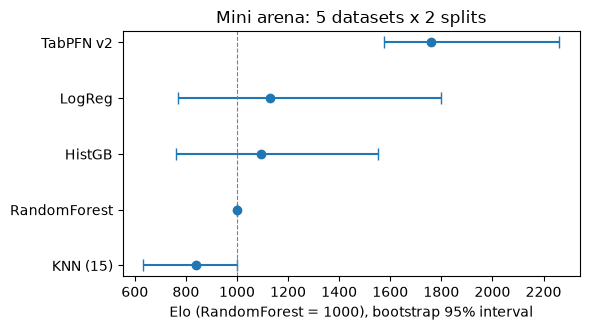

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.4))
order = arena_summary.index
low = [boot[m].quantile(0.025) for m in order]
high = [boot[m].quantile(0.975) for m in order]
center = arena_summary["Elo (RandomForest = 1000)"]
ax.errorbar(
    center,
    range(len(order)),
    xerr=[center - low, np.array(high) - center],
    fmt="o",
    capsize=4,
)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.axvline(1000, color="gray", lw=0.8, ls="--")
ax.set_xlabel("Elo (RandomForest = 1000), bootstrap 95% interval")
ax.set_title("Mini arena: 5 datasets x 2 splits")
plt.tight_layout()
plt.show()

## 5. 정리

| 집계 | 무엇을 보나 | 약점 |
|---|---|---|
| 그냥 평균 | 오차의 크기 | 크기가 큰 데이터셋 하나에 끌려간다 |
| 정규화 점수 | 데이터셋마다 최고 = 1, 중앙값 = 0 | 중앙값이 어느 모델이냐에 따라 바뀐다 |
| improvability | 가장 좋은 모델과의 오차 차이 비율 | 최고 모델 하나에 맞춘다 |
| 순위 | 데이터셋마다의 등수 | 차이의 크기를 버린다 |
| Elo | 모든 쌍의 승패를 설명하는 점수 | 차이의 크기를 버린다, 기준 모델이 필요하다 |

- 데이터셋 수가 적으면 Elo 구간이 넓어서, 모델 사이의 작은 차이는 가릴 수 없습니다. 이 저장소가 TabArena-Lite(51개)·BeyondArena-lite(78개 split)에서 판정할 때도 구간(TabArena-Lite는 ±60쯤)을 같이 봅니다.
- 실제 하네스: `minipfn.benchmarks.arena.run(suite, make_estimator, ...)`이 공식 split으로 돌리고, 집계는 `tabarena`의 `compare`가 합니다. 이 노트북의 `elo`는 같은 생각을 짧게 쓴 것이라 숫자가 똑같지는 않습니다.